In this example, we will apply 1CCCV protocol to our battery.
we will charge battery with 1C until battery reach Cut-off voltage (4.2V).
Then we continue with CV charge which means we remain voltage at 4.2 and charge until charge current reach to C/20 (0,25A)

In [30]:
import pybamm
import matplotlib.pyplot as plt
import numpy as np

In [31]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0) # Set initial state of charge to 0%
initial_soc = 0
Q_nom = parameter_values["Nominal cell capacity [A.h]"]

In [32]:
CCCV_Charging = pybamm.Experiment([
    "Charge at 1C until 4.2V", ## CC Phase will charge the battery at 1C until the voltage reaches 4.2V
    "Hold at 4.2 V until 250 mA", ## CV Phase will hold the voltage at 4.2V until the current drops to C/20 
])

In [33]:
model = pybamm.lithium_ion.DFN() # Create a DFN model

In [34]:
# Create a simulation object with the model, experiment, and parameter values
sim = pybamm.Simulation(model, experiment=CCCV_Charging, parameter_values=parameter_values) 

In [35]:
sol = sim.solve() # Solve the simulation
#sim.plot(["Voltage [V]", "Current [A]"], show_plot=True) # Plot the results in subplots

In [36]:
Solution = sim.solution.cycles
CC_Phase = Solution[0] # Get the first cycle (CC Phase) from the solution object
CV_Phase = Solution[1] # Get the second cycle (CV Phase) from the solution object

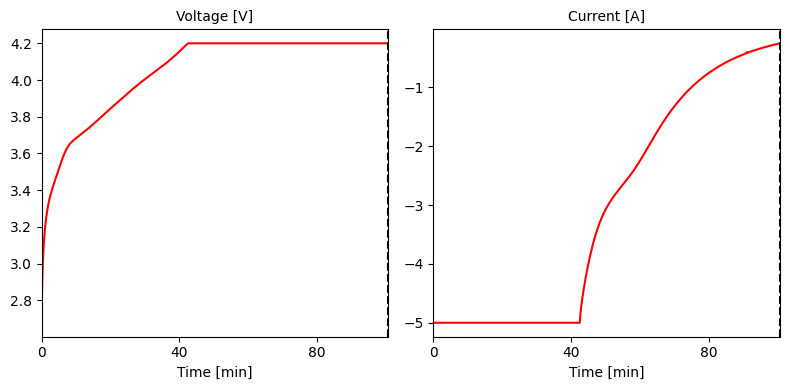

In [37]:
#Let's plot the voltage and current over time for the entire experiment using QuickPlot
qp = pybamm.QuickPlot(sim.solution,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp.plot(qp.max_t) # Plot the voltage and current over time for the entire experiment

In [38]:
t   = sol["Time [min]"].entries
soc = (initial_soc - sol["Discharge capacity [A.h]"].entries / Q_nom) * 100
t_switch   = sol.cycles[0]["Time [min]"].entries[-1]
soc_switch = np.interp(t_switch, t, soc) 


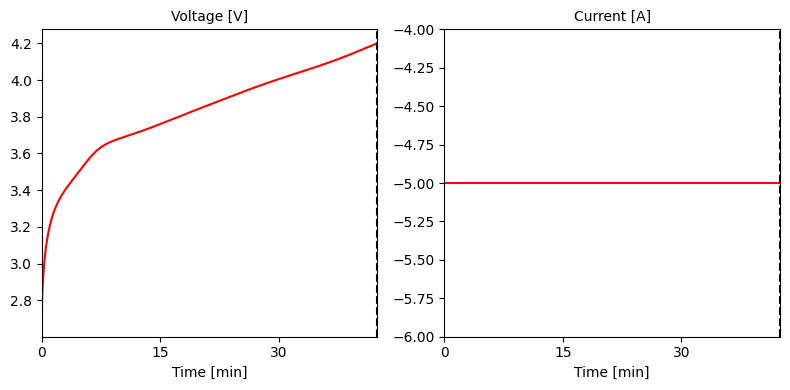

In [39]:
#Let's plot the voltage and current over time for the CC Phase using QuickPlot
qp_CC = pybamm.QuickPlot(CC_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CC.plot(qp_CC.max_t) # Plot the voltage and current over time for CC Phase

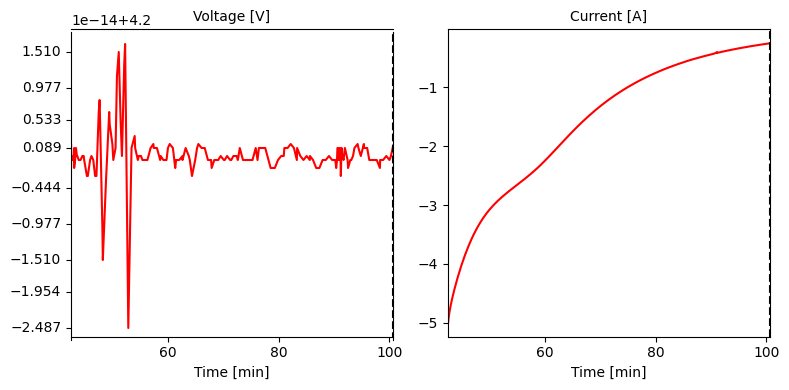

In [40]:
#Let's plot the voltage and current over time for the CV Phase using QuickPlot
qp_CV = pybamm.QuickPlot(CV_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CV.plot(qp_CV.max_t) # Plot the voltage and current over time for CV Phase

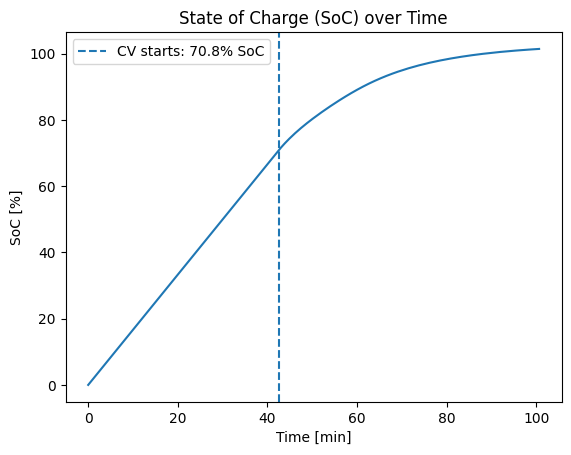

In [41]:
plt.plot(t, soc)
plt.axvline(t_switch, linestyle="--", label=f"CV starts: {soc_switch:.1f}% SoC")
plt.xlabel("Time [min]"); plt.ylabel("SoC [%]"); plt.legend()
plt.title("State of Charge (SoC) over Time")
plt.show()